<div style="background: linear-gradient(135deg, #003049 0%, #0a5c78 50%, #fcbf49 100%); padding: 40px 30px; border-radius: 16px; color: white; font-family: 'Segoe UI', sans-serif; margin-bottom: 10px;">
  <div style="display:flex; align-items:center; gap:16px; margin-bottom:12px;">
    <span style="font-size:48px;">🇲🇾</span>
    <div>
      <h1 style="margin:0; font-size:2rem; font-weight:800; letter-spacing:-0.5px;">LangChain & LangGraph MMU Exercise</h1>
      <p style="margin:0; font-size:1.1rem; opacity:0.9;">From Prompt to Multi-Agent System</p>
    </div>
  </div>
  <p style="margin:0 0 8px 0; font-size:0.95rem; opacity:0.85;">🎓 For MMU Computer Science Students &nbsp;·&nbsp; <strong>Topic:</strong> Tech Career Intelligence in Malaysia &amp; Southeast Asia</p>
  <p style="margin:0; font-size:0.85rem; opacity:0.7;">Explore the Malaysian tech job market — who's hiring, what skills matter, and where AI is taking careers — using progressively powerful AI tools.</p>
</div>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1vKFYc5ylBj6zYXuF-4u3b9Re2Lnl4FlC?usp=sharing)


---

### 🗺️ What You'll Build

| Exercise | Stack | Key Concept |
|----------|-------|-------------|
| **A** | LangChain + LLM + Prompt | LCEL pipe chain |
| **B** | + Structured Output | Pydantic schemas, typed responses |
| **C** | + Tools (scripted loop) | `bind_tools`, Tavily, Wikipedia, custom tool |
| **D** | LangGraph ReAct Agent | *Autonomous* tool use — agent decides what & when |
| **E** | LangGraph Multi-Agent | Supervisor → Scout → Analyst → Writer |

> **C vs D distinction:** In C you *script* the tool loop manually (you control when tools run). In D the agent *autonomously decides* which tools to call, in what order, and how many times — you just give it the tools and let it reason.


### ⚙️ Prerequisites

In [ ]:
!pip install langchain langchain-openai langchain-community langchain-tavily langgraph wikipedia rich ipywidgets matplotlib seaborn grandalf

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.6/99.6 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.2/552.2 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 78.3 MB/s eta 0:00:00
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11678 sha256=08eb30e076a75d3fb9c61b38f720a15b0bc29f5f23773b3b6f3fc47b53168326
  Stored in directory: /root/.cache/pip/wheels/63/47/7c/a9688349aa74d228ce0a9023229c6c0ac52ca2a40fe87679b8
Successfully built wikipedia
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
     

## ⚙️ 0 · Setup & Configuration

In [ ]:
import os
import json
import textwrap
import warnings
warnings.filterwarnings("ignore")

# ── Rich for beautiful terminal output ───────────────────────────────────────
from rich.console import Console
from rich.panel import Panel
from rich.table import Table
from rich.markdown import Markdown
from rich.progress import track
from rich import print as rprint

console = Console(width=100)

# ── API Keys ─────────────────────────────────────────────────────────────────
# Option 1 – set directly (dev only, never commit)
# os.environ["OPENAI_API_KEY"]  = "sk-..."
# os.environ["TAVILY_API_KEY"]  = "tvly-..."

# Option 2 – .env file (recommended)
try:
    from dotenv import load_dotenv
    load_dotenv()
    console.print("[green]✓[/green] .env loaded")
except ImportError:
    console.print("[yellow]ℹ[/yellow] python-dotenv not installed, using os.environ directly")

# ── Verify keys ───────────────────────────────────────────────────────────────
missing = [k for k in ("OPENAI_API_KEY", "TAVILY_API_KEY") if not os.getenv(k)]
if missing:
    console.print(f"[red]⚠ Missing API keys: {missing}[/red]")
    console.print("[dim]Set them above or in a .env file before running exercises C–E[/dim]")
else:
    console.print("[green]✓[/green] All API keys found")

# Option 3 - colab
import os
from google.colab import userdata

missing = [k for k in ("OPENAI_API_KEY", "TAVILY_API_KEY") if not os.getenv(k)]
if missing:
  try:
    os.environ["OPENAI_API_KEY"] = userdata.get("MDX_CST4265_OPENAI_API_KEY")
    os.environ["TAVILY_API_KEY"] = userdata.get("TAVILY_API_KEY")
  except:
    console.print(f"Colab keys failed. Please setup the secrets properly")

missing = [k for k in ("OPENAI_API_KEY", "TAVILY_API_KEY") if not os.getenv(k)]
if missing:
    console.print(f"[red]⚠ Missing API keys: {missing}[/red]")
    console.print("[dim]Set them above or in a .env file before running exercises C–E[/dim]")
else:
    console.print("[green]✓[/green] All API keys found")

# ── Shared LLM ────────────────────────────────────────────────────────────────
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5-nano")
console.print(f"[green]✓[/green] LLM ready: [bold]{llm.model_name}[/bold]")

TOPIC = "Tech careers and AI job market for computer science graduates in Malaysia and Southeast Asia"
console.print(f"\n[bold cyan]🎯 Research topic:[/bold cyan] {TOPIC}")


✓ .env loaded

⚠ Missing API keys: ['OPENAI_API_KEY', 'TAVILY_API_KEY']

Set them above or in a .env file before running exercises C–E

✓ All API keys found

✓ LLM ready: gpt-5-nano

🎯 Research topic: Tech careers and AI job market for computer science graduates in Malaysia and 
Southeast Asia

### 📊 Exercise Architecture Map

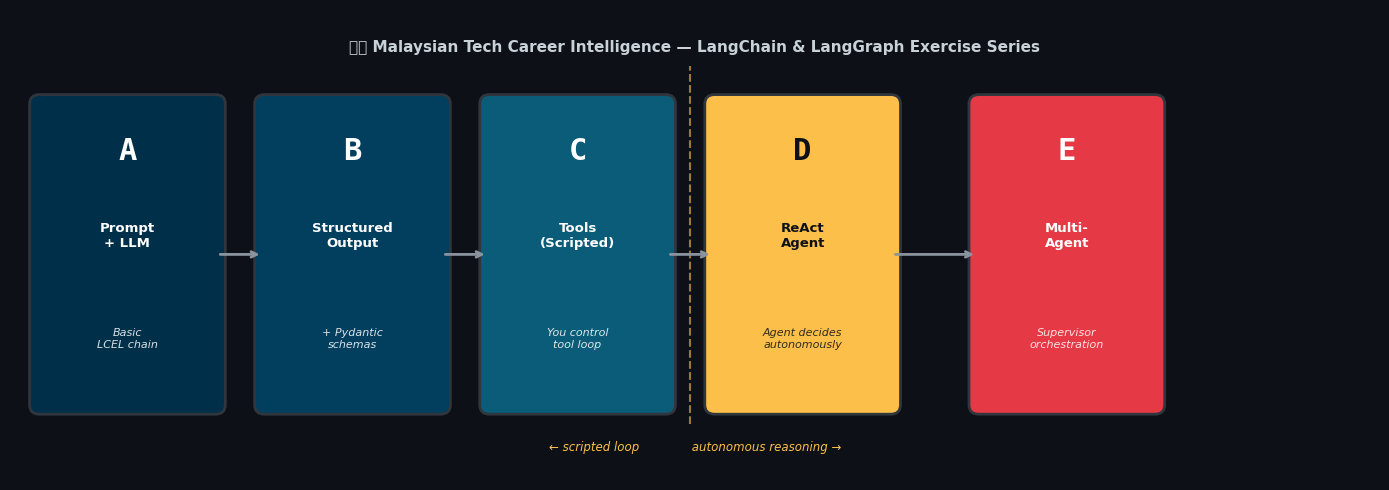

✓ Architecture map rendered


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import numpy as np

fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5)
ax.axis('off')
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#0d1117')

steps = [
    ("A", "Prompt\n+ LLM", "#003049", "Basic\nLCEL chain"),
    ("B", "Structured\nOutput", "#023e5e", "+ Pydantic\nschemas"),
    ("C", "Tools\n(Scripted)", "#0a5c78", "You control\ntool loop"),
    ("D", "ReAct\nAgent", "#fcbf49", "Agent decides\nautonomously"),
    ("E", "Multi-\nAgent", "#e63946", "Supervisor\norchestration"),
]

x_positions = [1.2, 3.5, 5.8, 8.1, 10.8]
text_color = ['white', 'white', 'white', '#0d1117', 'white']

for i, ((label, title, color, subtitle), x) in enumerate(zip(steps, x_positions)):
    # Main box
    box = mpatches.FancyBboxPatch((x-0.9, 0.8), 1.8, 3.2,
        boxstyle="round,pad=0.1", facecolor=color,
        edgecolor='#30363d', linewidth=2)
    ax.add_patch(box)
    ax.text(x, 3.5, label, ha='center', va='center', fontsize=22,
            fontweight='bold', color=text_color[i], fontfamily='monospace')
    ax.text(x, 2.6, title, ha='center', va='center', fontsize=9.5,
            fontweight='bold', color=text_color[i])
    ax.text(x, 1.5, subtitle, ha='center', va='center', fontsize=8,
            color=text_color[i], alpha=0.85, style='italic')

    # Arrow between boxes
    if i < len(steps) - 1:
        ax.annotate('', xy=(x_positions[i+1]-0.92, 2.4), xytext=(x+0.92, 2.4),
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=2))

# C→D special label
ax.text(7.0, 0.35, '← scripted loop              autonomous reasoning →',
        ha='center', va='center', fontsize=8.5, color='#fcbf49',
        style='italic', fontfamily='sans-serif')
ax.axvline(x=6.95, ymin=0.12, ymax=0.88, color='#fcbf49', lw=1.5, linestyle='--', alpha=0.6)

ax.text(7.0, 4.6, '🇲🇾 Malaysian Tech Career Intelligence — LangChain & LangGraph Exercise Series',
        ha='center', va='center', fontsize=11, color='#c9d1d9', fontweight='bold')

plt.tight_layout()
plt.savefig('architecture_map.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117', edgecolor='none')
plt.show()
print("✓ Architecture map rendered")


---
## 🅐 Exercise A · LangChain + LLM + Prompt

**Concept:** The simplest possible chain — a prompt template piped into an LLM and parsed as plain text.

```
ChatPromptTemplate  ──|──>  ChatOpenAI  ──|──>  StrOutputParser
```

**What you'll see:** How `ChatPromptTemplate` separates system instruction from user input, and how the LCEL `|` operator composes these into a runnable chain.


In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# ── Prompt ────────────────────────────────────────────────────────────────────
prompt_a = ChatPromptTemplate.from_messages([
    ("system",
     """You are a senior tech career advisor specialising in Malaysia and Southeast Asia.
You give practical, honest advice to CS graduates about the job market, in-demand
skills, and career paths. Use concrete examples relevant to companies in Malaysia
like Grab, AirAsia, Petronas Digital, MDEC, and local startups."""),
    ("human", "Give me a concise overview (5 bullet points) about: {topic}"),
])

# ── Chain ─────────────────────────────────────────────────────────────────────
chain_a = prompt_a | llm | StrOutputParser()

# ── Run ───────────────────────────────────────────────────────────────────────
console.print(Panel("[bold]Exercise A · Running basic LCEL chain...[/bold]",
                    style="blue", expand=False))

result_a = chain_a.invoke({"topic": TOPIC})

console.print(Panel(
    Markdown(result_a),
    title="[bold green]📋 Plain Text Response[/bold green]",
    subtitle="[dim]StrOutputParser — raw string[/dim]",
    border_style="green",
    padding=(1, 2)
))


╭──────────────────────────────────────────╮
│ Exercise A · Running basic LCEL chain... │
╰──────────────────────────────────────────╯

╭───────────────────────────────────── 📋 Plain Text Response ─────────────────────────────────────╮
│                                                                                                  │
│                                                                                                  │
│   • SEA and Malaysia are rapidly expanding for AI/tech roles, with strong demand across          │
│     fintech, e-commerce, travel and energy; big local players (Grab, AirAsia Digital, Petronas   │
│     Digital) and government initiatives via MDEC are actively hiring and funding AI adoption.    │
│   • Core roles and skills in demand for CS grads: AI/ML engineers, data scientists, data         │
│     engineers, and ML ops engineers; essential tools include Python, SQL, PyTorch/TensorFlow,    │
│     cloud platforms (AWS/Azure/GCP), Spark, and MLflow/Kubeflow.                                 │
│   • Career pathways you can target: graduate programs or internships at Grab Malaysia, AirAsia   │
│     Digital, Petronas Digital; opportunities in fast-growing local startups; potential for       │
│     regional SEA roles and cross-border teams.                                                   │
│   • How to break in: build tangible AI/data projects, contribute to open-source, participate in  │
│     hackathons or internships, pursue focused short courses, and tailor your portfolio to solve  │
│     real business problems (with clear results).                                                 │
│   • Market realities and outlook: competition is solid, but growth is persistent; you can        │
│     specialize in domains like computer vision, NLP, recommender systems, or ML platform         │
│     tooling; remote/hybrid roles are common across SEA, with strong potential for career         │
│     progression as you gain domain expertise.                                                    │
│                                                                                                  │
╰────────────────────────────────── StrOutputParser — raw string ──────────────────────────────────╯

### 🔍 What happened?
- `ChatPromptTemplate.from_messages` builds a prompt with **system** + **human** roles
- The `|` pipe composes `prompt → llm → parser` into one `Runnable`
- `.invoke({"topic": ...})` runs the full chain in one call
- Output is a plain `str` — no structure, no typing

**Next:** What if you need a *typed, validated* object instead of raw text?


---
## 🅑 Exercise B · LangChain + LLM + Prompt + Structured Output

**New concept:** Replace `StrOutputParser` with `llm.with_structured_output(Schema)`.  
The LLM is *instructed* to return JSON matching a Pydantic model — you get back a typed Python object.

```
ChatPromptTemplate  ──|──>  llm.with_structured_output(CareerReport)
```


In [ ]:
from pydantic import BaseModel, Field

# ── Schema (carries forward into later exercises) ─────────────────────────────
class CareerInsight(BaseModel):
    skill: str          = Field(description="Specific skill or technology")
    demand_level: str   = Field(description="High / Medium / Low demand")
    avg_salary_myr: int = Field(description="Estimated average monthly salary in MYR")
    top_companies: list[str] = Field(description="2–3 Malaysian/SEA companies hiring for this")
    trend: str          = Field(description="Growing / Stable / Declining")

class CareerReport(BaseModel):
    summary: str                  = Field(description="2-sentence executive summary")
    insights: list[CareerInsight] = Field(description="5–7 skill/role insights")
    hot_cities: list[str]         = Field(description="Top 3 cities in Malaysia for tech jobs")
    key_takeaway: str             = Field(description="Single most important advice for fresh grads")
    confidence: float             = Field(description="0.0–1.0 confidence in this analysis", ge=0, le=1)

# ── Structured chain ──────────────────────────────────────────────────────────
structured_llm_b = llm.with_structured_output(CareerReport)

prompt_b = ChatPromptTemplate.from_messages([
    ("system",
     "You are a Malaysian tech career analyst. Provide structured data about the "
     "tech job market for CS graduates in Malaysia and SEA. Be specific and data-driven."),
    ("human", "Analyse the career landscape for: {topic}"),
])

chain_b = prompt_b | structured_llm_b

# ── Run ───────────────────────────────────────────────────────────────────────
console.print(Panel("[bold]Exercise B · Running structured output chain...[/bold]",
                    style="cyan", expand=False))

report_b: CareerReport = chain_b.invoke({"topic": TOPIC})

# ── Rich table display ────────────────────────────────────────────────────────
t = Table(title="🇲🇾 Malaysian Tech Career Landscape", show_header=True,
          header_style="bold cyan", border_style="blue", show_lines=True)
t.add_column("Skill / Role", style="bold white", min_width=18)
t.add_column("Demand", justify="center", min_width=8)
t.add_column("Avg Salary (MYR/mo)", justify="right", min_width=10)
t.add_column("Trend", justify="center")
t.add_column("Top Companies", min_width=28)

demand_color = {"High": "green", "Medium": "yellow", "Low": "red"}
trend_icon   = {"Growing": "📈", "Stable": "➡️", "Declining": "📉"}

for ins in report_b.insights:
    color = demand_color.get(ins.demand_level, "white")
    icon  = trend_icon.get(ins.trend, "")
    t.add_row(
        ins.skill,
        f"[{color}]{ins.demand_level}[/{color}]",
        f"RM {ins.avg_salary_myr:,}",
        f"{icon} {ins.trend}",
        ", ".join(ins.top_companies),
    )
console.print(t)

console.print(Panel(
    f"[bold]Summary:[/bold] {report_b.summary}\n\n"
    f"[bold]Key Takeaway:[/bold] {report_b.key_takeaway}\n\n"
    f"[bold]Hot Cities:[/bold] {', '.join(report_b.hot_cities)}\n"
    f"[bold]Confidence:[/bold] {report_b.confidence:.0%}",
    title="[bold green]📊 Structured Report[/bold green]",
    border_style="green"
))


╭─────────────────────────────────────────────────╮
│ Exercise B · Running structured output chain... │
╰─────────────────────────────────────────────────╯

                                   🇲🇾 Malaysian Tech Career Landscape                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Skill / Role             ┃  Demand  ┃ Avg Salary (MYR/mo) ┃   Trend    ┃ Top Companies            
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━
│ Software Engineering     │   High   │            RM 5,500 │ 📈 Growing │ Grab Malaysia, Shopee    
│ (General)                │          │                     │            │ Malaysia, Petronas Digita
├──────────────────────────┼──────────┼─────────────────────┼────────────┼──────────────────────────
│ AI/ML Engineering        │   High   │            RM 8,000 │ 📈 Growing │ Grab Malaysia, Shopee    
│                          │          │                     │            │ Malaysia, NVIDIA SEA     
├──────────────────────────┼──────────┼─────────────────────┼────────────┼──────────────────────────
│ Data Science / Data      │   High   │            RM 7,000 │ 📈 Growing │ Shopee Malaysia, Petronas
│ Analytics                │          │                     │            │ Digital, Grab Malaysia   
├──────────────────────────┼──────────┼─────────────────────┼────────────┼──────────────────────────
│ Cloud & DevOps           │   High   │            RM 6,500 │ 📈 Growing │ Grab Malaysia, Petronas  
│                          │          │                     │            │ Digital, CelcomDigi      
├──────────────────────────┼──────────┼─────────────────────┼────────────┼──────────────────────────
│ Cybersecurity            │   High   │            RM 6,000 │ 📈 Growing │ CelcomDigi, Petronas     
│                          │          │                     │            │ Digital, Shopee Malaysia 
├──────────────────────────┼──────────┼─────────────────────┼────────────┼──────────────────────────
│ MLOps / AI               │   High   │            RM 7,500 │ 📈 Growing │ NVIDIA SEA, Grab Malaysia
│ Infrastructure           │          │                     │            │ Shopee Malaysia          
└──────────────────────────┴──────────┴─────────────────────┴────────────┴──────────────────────────

╭────────────────────────────────────── 📊 Structured Report ──────────────────────────────────────╮
│ Summary: The tech job market for Computer Science graduates in Malaysia and Southeast Asia is    │
│ expanding rapidly, driven by AI, cloud, data, and cybersecurity needs. While Singapore and       │
│ Malaysia remain the strongest hubs, SEA-wide demand is rising, with competitive salaries and a   │
│ growing emphasis on practical AI/ML, data literacy, and DevOps capabilities for fresh grads.     │
│                                                                                                  │
│ Key Takeaway: Fresh CS grads should fast-track AI/ML fundamentals, cloud basics, and hands-on    │
│ projects; secure internships with top SEA tech players and build a portfolio that demonstrates   │
│ practical problem-solving across software, data, and cloud environments.                         │
│                                                                                                  │
│ Hot Cities: Kuala Lumpur, Penang, Johor Bahru                                                    │
│ Confidence: 63%                                                                                  │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

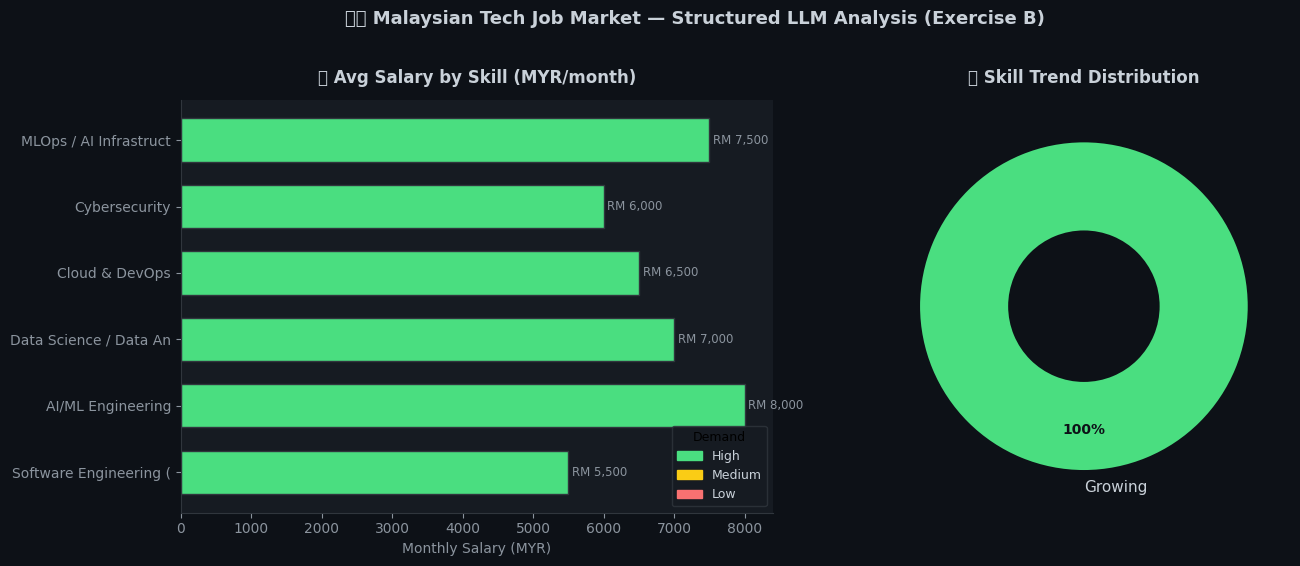

✓ Exercise B chart saved


In [ ]:
# ── Visualise the salary data ─────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

skills    = [ins.skill[:22] for ins in report_b.insights]
salaries  = [ins.avg_salary_myr for ins in report_b.insights]
demands   = [ins.demand_level for ins in report_b.insights]
trends    = [ins.trend for ins in report_b.insights]

d_colors  = {"High": "#4ade80", "Medium": "#facc15", "Low": "#f87171"}
bar_colors = [d_colors.get(d, "#60a5fa") for d in demands]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor('#0d1117')

# Bar chart - salaries
ax1.set_facecolor('#161b22')
bars = ax1.barh(skills, salaries, color=bar_colors, edgecolor='#30363d', height=0.65)
ax1.set_xlabel("Monthly Salary (MYR)", color='#8b949e', fontsize=10)
ax1.set_title("💼 Avg Salary by Skill (MYR/month)", color='#c9d1d9', fontsize=12, fontweight='bold', pad=12)
ax1.tick_params(colors='#8b949e')
ax1.spines['bottom'].set_color('#30363d')
ax1.spines['left'].set_color('#30363d')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
for bar, sal in zip(bars, salaries):
    ax1.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
             f'RM {sal:,}', va='center', color='#8b949e', fontsize=8.5)
legend_patches = [mpatches.Patch(color=c, label=l) for l, c in d_colors.items()]
ax1.legend(handles=legend_patches, title="Demand", loc='lower right',
           facecolor='#161b22', labelcolor='#c9d1d9', title_fontsize=9,
           fontsize=9, edgecolor='#30363d')

# Trend breakdown donut
trend_counts = {}
for t in trends:
    trend_counts[t] = trend_counts.get(t, 0) + 1
t_colors = {"Growing": "#4ade80", "Stable": "#60a5fa", "Declining": "#f87171"}
t_labels = list(trend_counts.keys())
t_vals   = list(trend_counts.values())
t_cols   = [t_colors.get(t, "#94a3b8") for t in t_labels]

ax2.set_facecolor('#161b22')
wedges, texts, autotexts = ax2.pie(t_vals, labels=t_labels, colors=t_cols,
    autopct='%1.0f%%', startangle=90, pctdistance=0.75,
    wedgeprops=dict(width=0.55, edgecolor='#0d1117', linewidth=2))
for text in texts: text.set_color('#c9d1d9'); text.set_fontsize(11)
for at in autotexts: at.set_color('#0d1117'); at.set_fontsize(10); at.set_fontweight('bold')
ax2.set_title("📈 Skill Trend Distribution", color='#c9d1d9', fontsize=12, fontweight='bold', pad=12)

plt.suptitle("🇲🇾 Malaysian Tech Job Market — Structured LLM Analysis (Exercise B)",
             color='#c9d1d9', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('exercise_b_chart.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117', edgecolor='none')
plt.show()
print("✓ Exercise B chart saved")


### 🔍 What changed from A?
- `llm.with_structured_output(CareerReport)` makes the LLM return a **validated Pydantic object**
- You can access `report.insights[0].skill` — no JSON parsing needed
- The schema becomes *documentation* of what you expect from the LLM

**Next:** What if the LLM needs *real-time* data from the web?


---
## 🅒 Exercise C · LangChain + LLM + Tools (Scripted Loop)

**New concept:** Give the LLM access to 3 tools via `bind_tools()`. The LLM can *request* tool calls,  
but **you** write the loop that decides when to execute them and when to stop.

**Tools:**
| Tool | Purpose |
|------|---------|
| 🌐 `TavilySearch` | Real-time web search via Tavily |
| 📖 `wikipedia_lookup` | Fetch Wikipedia summaries (custom `@tool`) |
| 🏢 `company_info_my` | Curated database of Malaysian tech companies (custom `@tool`) |

> ⚠️ **C vs D:** In this exercise, *you* script exactly when tools run and when to stop.  
> The agent in D makes those decisions itself.


In [ ]:
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage, SystemMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_tavily import TavilySearch
import wikipedia as wiki_lib

# ── Tool 1: Tavily web search ─────────────────────────────────────────────────
tavily_search = TavilySearch(
    max_results=4,
    topic="general",
    include_answer=True,
)

# ── Tool 2: Wikipedia lookup ──────────────────────────────────────────────────
@tool
def wikipedia_lookup(query: str) -> str:
    """Look up a factual topic on Wikipedia. Good for background info on
    technologies, companies, or concepts. Input should be a specific search term."""
    try:
        result = wiki_lib.search(query, results=1)
        if not result:
            return f"No Wikipedia article found for: {query}"
        page = wiki_lib.page(result[0], auto_suggest=False)
        summary = wiki_lib.summary(result[0], sentences=5, auto_suggest=False)
        return f"**{page.title}**\n{summary}\nSource: {page.url}"
    except Exception as e:
        return f"Wikipedia error: {str(e)}"

# ── Tool 3: Malaysian tech company database ───────────────────────────────────
MY_COMPANIES = {
    "grab": {"sector": "Super-app / Mobility", "hq": "Singapore (MY ops: KL)",
             "hiring_roles": ["ML Engineer", "Data Scientist", "Backend Engineer"],
             "tech_stack": ["Python", "Go", "Kafka", "Kubernetes"], "size": "5000+"},
    "airasia": {"sector": "Aviation / Digital", "hq": "Subang, Selangor",
                "hiring_roles": ["Cloud Engineer", "Full-Stack Developer", "Data Analyst"],
                "tech_stack": ["AWS", "React", "Python", "PostgreSQL"], "size": "3000+"},
    "petronas digital": {"sector": "Energy / Digital Transformation", "hq": "KLCC, Kuala Lumpur",
                         "hiring_roles": ["IoT Engineer", "AI/ML Specialist", "Cybersecurity"],
                         "tech_stack": ["Azure", "Python", "Power BI", "SAP"], "size": "1000+"},
    "mdec": {"sector": "Government / Tech Policy", "hq": "Cyberjaya",
             "hiring_roles": ["Programme Manager", "Digital Economy Analyst"],
             "tech_stack": ["N/A — policy org"], "size": "500+"},
    "axiata": {"sector": "Telecoms / Digital", "hq": "Kuala Lumpur",
               "hiring_roles": ["Network Engineer", "Data Engineer", "Product Manager"],
               "tech_stack": ["Python", "Spark", "AWS", "5G"], "size": "10000+"},
    "shopee": {"sector": "E-Commerce", "hq": "Singapore (MY ops: KL)",
               "hiring_roles": ["Backend Engineer", "Data Scientist", "DevOps"],
               "tech_stack": ["Java", "Python", "Kafka", "MySQL"], "size": "8000+"},
    "maxis": {"sector": "Telecoms", "hq": "Kuala Lumpur",
              "hiring_roles": ["Cloud Architect", "AI Engineer", "Cybersecurity"],
              "tech_stack": ["Azure", "Python", "Terraform", "5G"], "size": "5000+"},
}

@tool
def company_info_my(company_name: str) -> str:
    """Get hiring information, tech stack, and role openings for major Malaysian
    and SEA tech companies. Input the company name (e.g. 'Grab', 'AirAsia', 'Petronas Digital').
    Returns hiring roles, tech stack, and company details."""
    key = company_name.lower().strip()
    if key in MY_COMPANIES:
        c = MY_COMPANIES[key]
        return (f"**{company_name.title()}**\n"
                f"Sector: {c['sector']}\nHQ: {c['hq']}\nSize: {c['size']} employees\n"
                f"Hiring for: {', '.join(c['hiring_roles'])}\n"
                f"Tech stack: {', '.join(c['tech_stack'])}")
    # Fuzzy search
    matches = [k for k in MY_COMPANIES if key in k or k in key]
    if matches:
        k = matches[0]
        c = MY_COMPANIES[k]
        return (f"**{k.title()}** (closest match to '{company_name}')\n"
                f"Sector: {c['sector']}\nHiring: {', '.join(c['hiring_roles'])}\n"
                f"Stack: {', '.join(c['tech_stack'])}")
    available = ', '.join(MY_COMPANIES.keys())
    return f"Company not found. Available: {available}"

tools_c = [tavily_search, wikipedia_lookup, company_info_my]
console.print(f"[green]✓[/green] 3 tools registered: {[t.name for t in tools_c]}")


✓ 3 tools registered: ['tavily_search', 'wikipedia_lookup', 'company_info_my']

In [ ]:
# ── LLM with tools bound ──────────────────────────────────────────────────────
llm_with_tools_c = llm.bind_tools(tools_c)

# Build a lookup for tool execution
tool_map_c = {t.name: t for t in tools_c}

SYSTEM_C = """You are a Malaysian tech career advisor with access to web search,
Wikipedia, and a Malaysian company database. Use your tools to give
well-researched, specific answers about tech careers in Malaysia and SEA.
Always search for current info before answering.""".strip()

# ── SCRIPTED tool loop (YOU control when to stop) ─────────────────────────────
def run_scripted_c(question: str, max_rounds: int = 3) -> str:
    """
    C-style scripted loop:
    - We decide: 'run tools if LLM asks, stop after max_rounds'
    - This is explicit, predictable, but inflexible
    """
    messages = [
        SystemMessage(content=SYSTEM_C),
        HumanMessage(content=question),
    ]
    round_log = []

    for round_num in range(max_rounds + 1):
        response: AIMessage = llm_with_tools_c.invoke(messages)
        messages.append(response)

        if not (hasattr(response, "tool_calls") and response.tool_calls):
            # ← YOU decided: "no more tool calls = done"
            round_log.append(f"Round {round_num}: LLM gave final answer (no tools)")
            break

        # Execute each tool call — YOU wrote this loop
        for tc in response.tool_calls:
            round_log.append(f"Round {round_num}: 🔧 {tc['name']}({list(tc['args'].values())[0]!r:.40})")
            tool_result = tool_map_c[tc["name"]].invoke(tc["args"])
            messages.append(ToolMessage(
                content=str(tool_result),
                tool_call_id=tc["id"],
                name=tc["name"],
            ))

        if round_num == max_rounds:
            # ← YOU hard-stop after max rounds (scripted ceiling)
            round_log.append(f"Hit max rounds ({max_rounds}) — forcing finish")
            final = llm.invoke(messages + [HumanMessage(
                content="Summarise the research so far into a final answer.")])
            messages.append(final)

    return messages[-1].content, round_log

# ── Run ───────────────────────────────────────────────────────────────────────
console.print(Panel("[bold]Exercise C · Running scripted tool loop...[/bold]",
                    style="yellow", expand=False))

question_c = (
    "What are the most in-demand tech skills for fresh CS graduates in Malaysia in 2024? "
    "Check current web data and also look up what Grab and AirAsia are hiring for."
)
answer_c, logs_c = run_scripted_c(question_c)

# Show execution trace
trace_table = Table(title="🔄 Scripted Tool Loop Trace", border_style="yellow",
                    header_style="bold yellow", show_lines=False)
trace_table.add_column("Step", style="dim", min_width=8)
trace_table.add_column("Action", min_width=70)
for i, log in enumerate(logs_c, 1):
    trace_table.add_row(f"[{i}]", log)
console.print(trace_table)

console.print(Panel(Markdown(answer_c),
    title="[bold yellow]🌐 Research Answer (with real web data)[/bold yellow]",
    border_style="yellow", padding=(1,2)))


╭────────────────────────────────────────────╮
│ Exercise C · Running scripted tool loop... │
╰────────────────────────────────────────────╯

                             🔄 Scripted Tool Loop Trace                             
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Step     ┃ Action                                                                 ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ [1]      │ Round 0: 🔧 tavily_search('in-demand tech skills Malaysia 2024 fre)    │
│ [2]      │ Round 0: 🔧 tavily_search('Malaysia 2024 in-demand tech skills for)    │
│ [3]      │ Round 0: 🔧 company_info_my('Grab')                                    │
│ [4]      │ Round 0: 🔧 company_info_my('AirAsia')                                 │
│ [5]      │ Round 1: 🔧 tavily_search('most in-demand tech skills Malaysia 202)    │
│ [6]      │ Round 1: 🔧 tavily_search('Malaysia 2024 in-demand tech skills for)    │
│ [7]      │ Round 1: 🔧 company_info_my('Grab')                                    │
│ [8]      │ Round 1: 🔧 company_info_my('AirAsia')                                 │
│ [9]      │ Round 2: 🔧 tavily_search('most in-demand tech skills Malaysia 202)    │
│ [10]     │ Round 2: 🔧 tavily_search('Malaysia 2024 in-demand tech skills fre)    │
│ [11]     │ Round 2: 🔧 company_info_my('Grab')                                    │
│ [12]     │ Round 2: 🔧 company_info_my('AirAsia')                                 │
│ [13]     │ Round 3: 🔧 tavily_search('PIKOM Economic and Digital Job Market O)    │
│ [14]     │ Hit max rounds (3) — forcing finish                                    │
└──────────┴────────────────────────────────────────────────────────────────────────┘

╭──────────────────────────── 🌐 Research Answer (with real web data) ─────────────────────────────╮
│                                                                                                  │
│  Here’s a concise, research-backed summary of the most in-demand tech skills for fresh CS        │
│  graduates in Malaysia in 2024, plus what Grab and AirAsia were hiring for.                      │
│                                                                                                  │
│   1 What the 2024 market looked like (Malaysia)                                                  │
│                                                                                                  │
│   • In-demand roles for fresh graduates broadly included:                                        │
│      • Software engineering / development                                                        │
│      • Data analytics / data science                                                             │
│      • AI/ML engineering                                                                         │
│      • Cloud/DevOps and cloud architecture                                                       │
│      • Cybersecurity                                                                             │
│      • Full-stack / backend developers                                                           │
│      • Data analysis and business intelligence                                                   │
│   • Key drivers:                                                                                 │
│      • Strong digital transformation across sectors (fintech, e-commerce, manufacturing,         │
│        transport)                                                                                │
│      • Large gap in digital/talent supply noted by agencies and industry bodies                  │
│      • Salary evidence for fresh grads typically in the RM3,500–RM5,000/month range (with        │
│        higher ranges for some high-demand, specialized roles)                                    │
│      • “Golden Pillars” of demand highlighted by PIKOM/MDEC: AI/ML, cybersecurity, cloud         │
│        computing, data engineering                                                               │
│   • Indicative data points cited by multiple sources (2024):                                     │
│      • Fresh-graduate software engineer salaries around RM3,500–RM5,000; data on higher ranges   │
│        for AI/ML, cloud/DevOps in some reports                                                   │
│      • A large number of digital roles remained unfilled (illustrating tight talent supply)      │
│      • Core tech stacks and skills mentioned repeatedly: Python/Java, SQL, cloud platforms       │
│        (AWS/Azure/GCP), data analytics, Kubernetes/Docker, CI/CD, cybersecurity fundamentals     │
│                                                                                                  │
│   2 Core in-demand skills for fresh CS grads in 2024                                             │
│                                                                                                  │
│   • Programming and software development                                                         │
│      • Python, Java, JavaScript/TypeScript; basic algorithms/data structures; RESTful services;  │
│        microservices                                                                             │
│   • Cloud and DevOps                                                                             │
│      • Cloud platforms (AWS, Azure, GCP); containerization (Docker); orchestration               │
│        (Kubernetes); CI/CD                                                                       │
│   • Data and analytics                                                                           │
│      • SQL and data querying; data visualization basics; dat

### 🔍 What changed from B?
- `llm.bind_tools(tools)` tells the LLM it *can* call tools
- **You write the loop**: check for `response.tool_calls`, execute them, feed `ToolMessage` back
- **The ceiling is explicit**: `max_rounds` is set by you — the LLM cannot choose to do more
- The answer is grounded in **real-time web data** + company database + Wikipedia

**Key limitation of C:** The LLM can't "ask follow-up questions" or dynamically chain tools across multiple reasoning cycles. That's what D solves.


---
## 🅓 Exercise D · LangGraph ReAct Agent (Autonomous)

**The fundamental difference from C:**

| | Exercise C | Exercise D |
|---|---|---|
| Who controls the loop? | **You** (explicit Python loop) | **The agent** (autonomous reasoning) |
| Can it ask follow-ups? | ❌ Fixed rounds | ✅ Calls tools as many times as it judges needed |
| Can it chain tools freely? | ❌ One pass per round | ✅ Tool A result → decide to call Tool B → decide to call Tool C |
| Extra questions? | ❌ Scripted | ✅ Agent re-queries the same tool with a refined query |

We use `create_react_agent` from LangGraph — the standard prebuilt ReAct agent.  
The graph is: `[agent node] ↔ [tool node]` — it loops until the LLM stops calling tools.


In [ ]:
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import HumanMessage

# ── Same 3 tools — identical to C ─────────────────────────────────────────────
tools_d = [tavily_search, wikipedia_lookup, company_info_my]

# ── Memory for multi-turn conversation ───────────────────────────────────────
memory = MemorySaver()

# ── System prompt — tells agent HOW to reason, not what to do ─────────────────
SYSTEM_D = """You are an expert Malaysian tech career intelligence agent.

You have access to three tools:
- tavily_search: Real-time web search for current job market data
- wikipedia_lookup: Background info on technologies and companies
- company_info_my: Hiring data for specific Malaysian/SEA tech companies

Your reasoning strategy:
1. Start with a broad web search to understand the landscape
2. Use wikipedia_lookup if you need background on specific technologies
3. Use company_info_my for specific company hiring details
4. If initial results raise new questions, search AGAIN with more specific queries
5. Keep going until you have genuinely comprehensive, specific information
6. You decide when you have enough information — don't stop prematurely

You are NOT limited in tool calls. Use as many as you need.
ALWAYS be specific to Malaysia and Southeast Asia context.""".strip()

# ── Build the agent ───────────────────────────────────────────────────────────
agent_d = create_react_agent(
    model=llm,
    tools=tools_d,
    checkpointer=memory,
    prompt=SYSTEM_D,
)
console.print("[green]✓[/green] LangGraph ReAct agent compiled")
console.print("[dim]Graph: [agent] ↔ [tools] — loops autonomously until done[/dim]")


✓ LangGraph ReAct agent compiled

Graph:  ↔  — loops autonomously until done

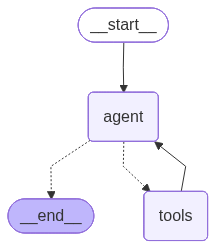

In [ ]:
from IPython.display import Image
Image(agent_d.get_graph().draw_mermaid_png())

In [ ]:
import time

def run_agent_d(question: str, thread_id: str = "my_thread_1") -> dict:
    """Run the autonomous agent — it decides tool use, chaining, and when to stop."""
    config = {"configurable": {"thread_id": thread_id}}
    tool_calls_log = []

    console.print(Panel(
        f"[bold]Question:[/bold] {question}",
        title="[bold magenta]Exercise D · Autonomous ReAct Agent[/bold magenta]",
        border_style="magenta", expand=False
    ))
    console.print()

    # Stream events so we can observe the agent's decisions
    for event in agent_d.stream(
        {"messages": [HumanMessage(content=question)]},
        config=config,
        stream_mode="updates",
    ):
        for node_name, node_data in event.items():
            msgs = node_data.get("messages", [])
            for msg in msgs:
                if hasattr(msg, "tool_calls") and msg.tool_calls:
                    for tc in msg.tool_calls:
                        arg_preview = str(list(tc["args"].values())[0])[:55] if tc["args"] else ""
                        console.print(f"  [magenta]🤖 Agent decides:[/magenta] call [bold]{tc['name']}[/bold]([italic]{arg_preview!r}[/italic])")
                        tool_calls_log.append({"tool": tc["name"], "args": tc["args"]})
                elif isinstance(msg, ToolMessage):
                    preview = str(msg.content)[:80].replace("\n", " ")
                    console.print(f"  [cyan]📦 Tool result:[/cyan] {preview}…")
                elif hasattr(msg, "content") and msg.content and node_name == "agent":
                    if not (hasattr(msg, "tool_calls") and msg.tool_calls):
                        console.print(f"  [green]✅ Agent final answer ready[/green]")

    # Get final state
    final_state = agent_d.get_state(config)
    final_answer = final_state.values["messages"][-1].content
    return {"answer": final_answer, "tool_calls": tool_calls_log}

# ── Run with a question the agent must reason over autonomously ───────────────
question_d = (
    "I'm a Malaysian CS student graduating in 2025. I want to maximise my salary. "
    "What combination of skills should I focus on? "
    "Which specific companies in Malaysia pay the most? "
    "Is AI/ML worth pursuing or is cloud/DevOps more practical right now?"
)

result_d = run_agent_d(question_d)


╭────────────────────────────── Exercise D · Autonomous ReAct Agent ───────────────────────────────╮
│ Question: I'm a Malaysian CS student graduating in 2025. I want to maximise my salary. What      │
│ combination of skills should I focus on? Which specific companies in Malaysia pay the most? Is   │
│ AI/ML worth pursuing or is cloud/DevOps more practical right now?                                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

🤖 Agent decides: call tavily_search('Malaysia software engineer salary 2024 2025 Malaysia pa')

🤖 Agent decides: call tavily_search('Malaysia top paying tech companies salary')

🤖 Agent decides: call tavily_search('AI ML demand Malaysia salary cloud DevOps Malaysia')

🤖 Agent decides: call tavily_search('Petronas Digital salary Malaysia software engineer')

🤖 Agent decides: call tavily_search('Grab Malaysia salary software engineer')

... (12 outputs left out)

📦 Tool result: {"query": "Sea Malaysia salary Garena Malaysia", "follow_up_questions": null, "a…

📦 Tool result: {"query": "Malaysia AI engineer salary", "follow_up_questions": null, "answer": …

📦 Tool result: {"query": "Malaysia DevOps engineer salary", "follow_up_questions": null, "answe…

✅ Agent final answer ready

In [ ]:
# ── Show the answer ───────────────────────────────────────────────────────────
console.print()
console.print(Panel(
    Markdown(result_d["answer"]),
    title="[bold magenta]🤖 Autonomous Agent Answer[/bold magenta]",
    subtitle=f"[dim]{len(result_d['tool_calls'])} autonomous tool decisions made[/dim]",
    border_style="magenta",
    padding=(1, 2)
))

# ── Multi-turn follow-up (agent remembers context!) ───────────────────────────
console.print()
console.print("[bold]💬 Follow-up question (agent remembers the conversation)...[/bold]")
console.print()

follow_up = "Based on what you just told me — which single company should I apply to first and why?"
result_followup = run_agent_d(follow_up, thread_id="my_thread_1")  # same thread!

console.print(Panel(
    Markdown(result_followup["answer"]),
    title="[bold magenta]🤖 Follow-up Answer (with memory)[/bold magenta]",
    border_style="magenta", padding=(1, 2)
))


╭─────────────────────────────────── 🤖 Autonomous Agent Answer ───────────────────────────────────╮
│                                                                                                  │
│  Short answer up front                                                                           │
│                                                                                                  │
│   • If you want the highest payoff in Malaysia, aim for top-tier tech MNCs and                   │
│     fintech/e-commerce platforms in KL (Grab, Google, Petronas Digital, Cisco, Shell, etc.).     │
│     Data from self-reported salary sites puts top routes around RM100k–RM200k+ total             │
│     compensation per year for mid-senior levels; entry levels are much lower but grow fast with  │
│     experience.                                                                                  │
│   • AI/ML can be highly lucrative in Malaysia, especially with MLOps, large-language-model       │
│     deployment, and cloud integration. Cloud/DevOps remains extremely practical and in-demand,   │
│     often offering strong mid-career salaries and clearer paths to promotions and seniority.     │
│   • The best plan is a dual-track: build solid software fundamentals, plus a targeted            │
│     specialization in AI/ML or Cloud/DevOps (or both over time). Actively develop                │
│     production-grade projects and cloud/MLOps skills to stand out.                               │
│                                                                                                  │
│  What skills to focus on to maximise salary (Malaysia-specific)                                  │
│                                                                                                  │
│   1 Core foundation (everyone should have this)                                                  │
│                                                                                                  │
│   • Strong software engineering fundamentals: data structures, algorithms, complexity, clean     │
│     coding, testing, debugging.                                                                  │
│   • Proficiency in at least one strong backend language (Java, Python, Go) and one               │
│     frontend/Full-Stack capability (React/Node.js or similar).                                   │
│   • Solid CS basics for interviews (system design fundamentals, databases, APIs).                │
│                                                                                                  │
│   2 If you want the fastest path to high pay: specialization tracks with market signals for      │
│     Malaysia                                                                                     │
│                                                                                                  │
│   • Track A: AI/ML with MLOps                                                                    │
│      • Core: Python, NumPy/pandas, scikit-learn.                                                 │
│      • ML frameworks: PyTorch or TensorFlow.                                                     │
│      • End-to-end ML lifecycle: data prep, model training, evaluation, deployment.               │
│      • MLOps: MLflow, Kubeflow, Docker, Kubernetes, CI/CD for ML pipelines.                      │
│      • Cloud/Platform: experience with AWS, Azure, or Google Cloud (compute, storage, ML         │
│        services).                                                                                │
│      • Data/ops tooling: versioning, experiments tracking, reproducibility, monitoring model     │
│        drift.                                                                                    │
│      • Bonus: exposure to LLMs, embeddings, prompt engineering, AI ethics, model safety basics.  │
│      • Why it pays: Malaysia has growing demand for AI-enabl

💬 Follow-up question (agent remembers the conversation)...

╭────────────────────────────── Exercise D · Autonomous ReAct Agent ───────────────────────────────╮
│ Question: Based on what you just told me — which single company should I apply to first and why? │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

🤖 Agent decides: call company_info_my('Grab')

📦 Tool result: **Grab** Sector: Super-app / Mobility HQ: Singapore (MY ops: KL) Size: 5000+ emp…

✅ Agent final answer ready

╭─────────────────────────────── 🤖 Follow-up Answer (with memory) ────────────────────────────────╮
│                                                                                                  │
│  Recommendation: Apply to Grab first (Malaysia KL ops)                                           │
│                                                                                                  │
│  Why Grab fits best for a 2025 graduate aiming to maximize salary in Malaysia                    │
│                                                                                                  │
│   • High pay signal in Malaysia: Grab is consistently among the top-paying tech employers in     │
│     the country for software engineers, often offering strong base plus equity/RSU components    │
│     at mid–senior levels. This makes it a prime entry point for earning growth in KL.            │
│   • Local KL advantage with global scale: Grab’s KL team gives you the opportunity to work on    │
│     large-scale, production-grade systems without needing to relocate abroad. You can gain       │
│     exposure to high-impact projects while staying in Malaysia.                                  │
│   • Role alignment with in-demand tech: The listed openings (ML Engineer, Data Scientist,        │
│     Backend Engineer) map directly to the skills you’re likely building (Python, distributed     │
│     systems, modern data pipelines). The tech stack you mentioned (Python, Kafka, Kubernetes,    │
│     Go) is actively used at Grab, which helps your on-boarding and career progression.           │
│   • Clear path to rapid career growth: As one of Southeast Asia’s marquee tech platforms, Grab   │
│     offers structured career ladders, visibility for performance-based raises, and               │
│     opportunities to move into higher-responsibility roles and potentially equity-heavy          │
│     packages over time.                                                                          │
│   • Practical, high-demand domain exposure: Working at Grab puts you in                          │
│     fintech/e-commerce/mobility data domains, which are highly valued in Malaysia and Southeast  │
│     Asia. This boosts long-term salary potential as you gain domain expertise.                   │
│                                                                                                  │
│  What to target in your application                                                              │
│                                                                                                  │
│   • Roles: ML Engineer or Backend Engineer (focus on building scalable services and data         │
│     pipelines; if you want ML depth early, emphasize ML lifecycle, model deployment, and data    │
│     systems in your projects).                                                                   │
│   • Skills to highlight in your resume: Python for ML/MD pipelines, Kafka-based data streaming   │
│     or event-driven architectures, Kubernetes/containerized deployments, REST/gRPC services,     │
│     any cloud exposure (AWS/Azure/GCP), and hands-on ML projects (end-to-end pipeline,           │
│     monitoring, and some production-like usage).                                                 │
│   • Projects to showcase: 1–2 end-to-end projects with measurable impact (e.g., a data           │
│     ingestion + model inference pipeline deployed in a containerized environment, with           │
│     monitoring/alerting). Include architecture diagrams or brief design notes.                   │
│                                                                                                  │
│  Next steps                                                                                      │
│                                                                                                  │
│   • Update your resume and LinkedIn with a tight 1-page high

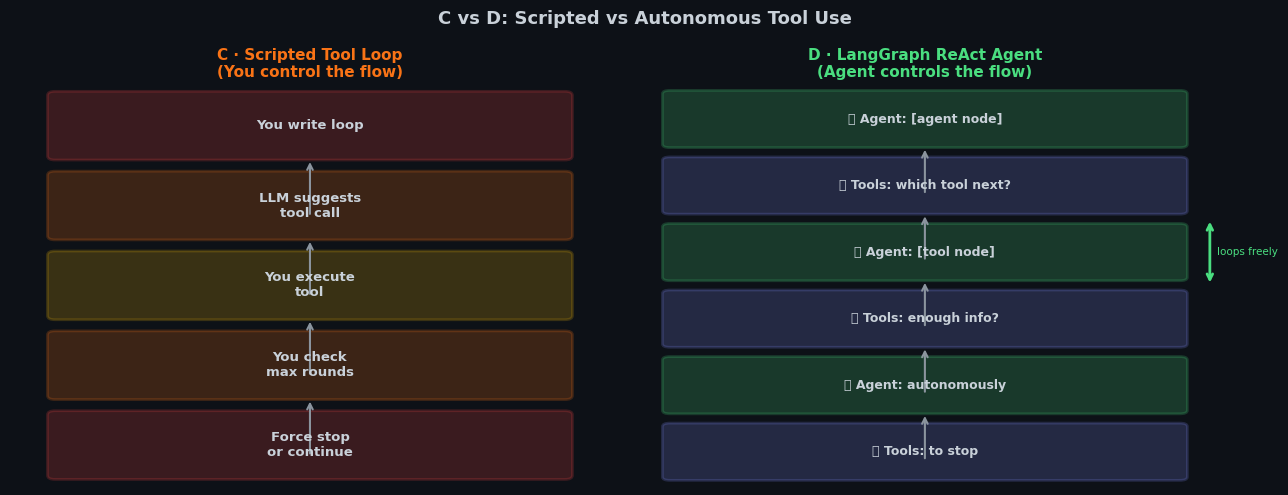

✓ C vs D comparison chart saved


In [ ]:
# ── Visualise: C vs D tool call comparison ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('#0d1117')

# C — scripted, predictable
c_steps = ["You write loop", "LLM suggests\ntool call", "You execute\ntool",
           "You check\nmax rounds", "Force stop\nor continue"]
c_colors = ["#ef4444", "#f97316", "#eab308", "#f97316", "#ef4444"]

ax1 = axes[0]
ax1.set_facecolor('#161b22')
ax1.set_xlim(0, 4)
ax1.set_ylim(-0.5, len(c_steps) - 0.5)
ax1.axis('off')
ax1.set_title("C · Scripted Tool Loop\n(You control the flow)",
              color='#f97316', fontsize=11, fontweight='bold')
for i, (step, color) in enumerate(zip(c_steps, c_colors)):
    y = len(c_steps) - 1 - i
    box = mpatches.FancyBboxPatch((0.3, y-0.38), 3.4, 0.76,
        boxstyle="round,pad=0.05", facecolor=color, alpha=0.2,
        edgecolor=color, linewidth=2)
    ax1.add_patch(box)
    ax1.text(2.0, y, step, ha='center', va='center',
             color='#c9d1d9', fontsize=9.5, fontweight='bold')
    if i < len(c_steps)-1:
        ax1.annotate('', xy=(2.0, y-0.42), xytext=(2.0, y-0.38+(-0.76)),
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1.5))

# D — autonomous, flexible
d_steps = ["LangGraph\n[agent node]", "Agent reasons:\nwhich tool next?",
           "LangGraph\n[tool node]", "Agent reasons:\nenough info?",
           "Loop continues\nautonomously", "Agent decides\nto stop"]
d_colors_list = ["#4ade80"]*len(d_steps)

ax2 = axes[1]
ax2.set_facecolor('#161b22')
ax2.set_xlim(0, 4)
ax2.set_ylim(-0.5, len(d_steps) - 0.5)
ax2.axis('off')
ax2.set_title("D · LangGraph ReAct Agent\n(Agent controls the flow)",
              color='#4ade80', fontsize=11, fontweight='bold')
for i, step in enumerate(d_steps):
    y = len(d_steps) - 1 - i
    is_agent = i % 2 == 0
    color = "#4ade80" if is_agent else "#818cf8"
    box = mpatches.FancyBboxPatch((0.3, y-0.38), 3.4, 0.76,
        boxstyle="round,pad=0.05", facecolor=color, alpha=0.2,
        edgecolor=color, linewidth=2)
    ax2.add_patch(box)
    label = "🤖 Agent" if is_agent else "🔧 Tools"
    ax2.text(2.0, y, f"{label}: {step.split(chr(10))[1] if chr(10) in step else step}",
             ha='center', va='center', color='#c9d1d9', fontsize=9, fontweight='bold')
    if i < len(d_steps)-1:
        ax2.annotate('', xy=(2.0, y-0.42), xytext=(2.0, y-0.38+(-0.76)),
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1.5))

# Bidirectional arrow for D
ax2.annotate('', xy=(3.9, 2.5), xytext=(3.9, 3.5),
    arrowprops=dict(arrowstyle='<->', color='#4ade80', lw=2))
ax2.text(3.95, 3.0, 'loops freely', va='center', color='#4ade80', fontsize=7.5)

plt.suptitle("C vs D: Scripted vs Autonomous Tool Use",
             color='#c9d1d9', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('exercise_cd_comparison.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117', edgecolor='none')
plt.show()
print("✓ C vs D comparison chart saved")


### 🔍 Key differences you observed
- **C**: You wrote `for round_num in range(max_rounds)` — it's your Python loop  
- **D**: `create_react_agent` builds a graph that loops `agent ↔ tools` on its own  
- **D can ask follow-up questions** internally — it may call `tavily_search` *three times* with different queries if it needs more info  
- **D has memory** — the `MemorySaver` checkpointer lets it remember previous turns in the same thread  
- **D's stopping condition** is the LLM's judgment, not your `max_rounds` variable


---
## 🅔 Exercise E · LangGraph Multi-Agent System

**New concept:** Multiple specialised agents, each with their own tools and system prompt,  
coordinated by a **Supervisor** that routes between them.

```
[Supervisor] → [Scout Agent]    (web search specialist)
[Supervisor] → [Analyst Agent]  (structured analysis + salary data)  
[Supervisor] → [Writer Agent]   (final report writer)
[Writer] → END
```

The Supervisor uses `with_structured_output` to produce a typed routing decision.  
Each agent has its own `create_react_agent` with its own tool subset.


In [ ]:
from typing import Annotated, TypedDict, Literal
from langchain_core.messages import BaseMessage
from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field

# ── Shared Team State ─────────────────────────────────────────────────────────
class TeamState(TypedDict):
    messages:     Annotated[list[BaseMessage], add_messages]
    topic:        str
    raw_research: str
    analysis:     str
    salary_data:  dict
    final_report: str
    next_agent:   str
    iterations:   int

# ── Supervisor Routing Schema ─────────────────────────────────────────────────
class SupervisorDecision(BaseModel):
    next: Literal["scout", "analyst", "writer", "FINISH"] = Field(
        description="Which specialist to call next, or FINISH when report is ready.")
    reasoning: str = Field(description="One-sentence explanation.")

# ── LLMs ──────────────────────────────────────────────────────────────────────
supervisor_llm = ChatOpenAI(model="gpt-5-nano")
agent_llm      = ChatOpenAI(model="gpt-5-nano")

console.print("[green]✓[/green] Multi-agent components ready")


✓ Multi-agent components ready

In [ ]:
# ── Specialist Agent: Scout ───────────────────────────────────────────────────
# Scout only gets search tools — its job is raw data gathering
scout_tools = [tavily_search, wikipedia_lookup]

scout_agent = create_react_agent(
    model=agent_llm,
    tools=scout_tools,
    prompt="""You are a research scout specialising in Malaysian tech job markets.
Your ONLY job: gather raw, factual data using web search and Wikipedia.
Search multiple angles: salary surveys, job postings, skill demand reports,
company expansions, government tech initiatives (MDEC, MSC Malaysia).
DO NOT analyse — just gather comprehensive raw data with sources.""",
)

# ── Specialist Agent: Analyst ─────────────────────────────────────────────────
# Analyst gets the company database tool for deep-dive company analysis
analyst_tools = [company_info_my, tavily_search]

analyst_agent = create_react_agent(
    model=agent_llm,
    tools=analyst_tools,
    prompt="""You are a critical analyst for Malaysian tech careers.
Given raw research, you:
1. Look up specific companies in the database to validate claims
2. Cross-reference salary data across sources
3. Identify skill gaps and emerging opportunities
4. Assess confidence levels for each finding (High/Medium/Low)
5. Flag what's specifically relevant for fresh CS graduates in Malaysia
Be rigorous, sceptical, and data-driven.""",
)

# ── Writer Agent ──────────────────────────────────────────────────────────────
# Writer has no tools — it only synthesises
def writer_node(state: TeamState) -> dict:
    writer_llm = ChatOpenAI(model="gpt-5-nano")
    response = writer_llm.invoke([
        SystemMessage(content="""You are a professional technical writer creating
a career guide for Malaysian CS students. Write a polished markdown report with:

# 🇲🇾 [Title]
## Executive Summary
## Top In-Demand Skills (table with demand/salary)
## Best Companies to Target (with why)
## Career Paths (3 options: AI/ML, Cloud/DevOps, Full-Stack)
## 6-Month Action Plan for Fresh Grads
## Salary Expectations by Experience Level
## Key Resources (local: MDEC, TalentCorp, JobStreet)

Be specific to Malaysia. Use real numbers where available."""),
        HumanMessage(content=(
            f"Topic: {state['topic']}\n\n"
            f"Raw Research:\n{state['raw_research']}\n\n"
            f"Analysis:\n{state['analysis']}"
        )),
    ])
    return {"final_report": response.content}

console.print("[green]✓[/green] Scout, Analyst, and Writer agents ready")


✓ Scout, Analyst, and Writer agents ready

In [ ]:
# ── Supervisor Node ────────────────────────────────────────────────────────────
SUPERVISOR_PROMPT = """You manage a 3-agent research team:
• scout   — web search & raw data gathering (do this FIRST, can do twice)
• analyst — critical analysis using company database (do AFTER scout)
• writer  — final polished report (do LAST, then FINISH)

Typical flow: scout → scout (optional) → analyst → writer → FINISH

Current state:
- raw_research filled: {has_raw}
- analysis filled: {has_analysis}
- final_report filled: {has_report}
- iterations: {iterations}

Decide who acts next.""".strip()

def supervisor_node(state: TeamState) -> dict:
    decision: SupervisorDecision = supervisor_llm.with_structured_output(
        SupervisorDecision
    ).invoke([
        SystemMessage(content=SUPERVISOR_PROMPT.format(
            has_raw=bool(state["raw_research"]),
            has_analysis=bool(state["analysis"]),
            has_report=bool(state["final_report"]),
            iterations=state["iterations"],
        )),
        HumanMessage(content=f"Topic: {state['topic']}. What next?"),
    ])
    console.print(f"  [bold blue]👔 Supervisor[/bold blue] → [bold]{decision.next}[/bold]: {decision.reasoning}")
    return {"next_agent": decision.next, "iterations": state["iterations"] + 1}

# ── Scout Node ─────────────────────────────────────────────────────────────────
def scout_node(state: TeamState) -> dict:
    console.print("  [cyan]🔭 Scout[/cyan] searching the web...")
    result = scout_agent.invoke(
        {"messages": [HumanMessage(content=f"Research: {state['topic']}")]}
    )
    raw = result["messages"][-1].content
    console.print(f"  [cyan]✓ Scout[/cyan] gathered {len(raw):,} chars")
    existing = state.get("raw_research", "")
    return {"raw_research": existing + "\n\n" + raw if existing else raw}

# ── Analyst Node ───────────────────────────────────────────────────────────────
def analyst_node(state: TeamState) -> dict:
    console.print("  [yellow]🧪 Analyst[/yellow] deep-diving the data...")
    result = analyst_agent.invoke({
        "messages": [HumanMessage(content=(
            f"Analyse this research for Malaysian CS graduates:\n\n"
            f"Topic: {state['topic']}\n\n"
            f"Raw data:\n{state['raw_research'][:3000]}"
        ))]
    })
    analysis = result["messages"][-1].content
    console.print(f"  [yellow]✓ Analyst[/yellow] produced {len(analysis):,} chars")
    return {"analysis": analysis}

# ── Routing ────────────────────────────────────────────────────────────────────
def route_supervisor(state: TeamState) -> str:
    if state["iterations"] >= 7:
        return "writer"
    return state["next_agent"]

# ── Build Graph ────────────────────────────────────────────────────────────────
def build_team_graph():
    g = StateGraph(TeamState)
    g.add_node("supervisor", supervisor_node)
    g.add_node("scout",      scout_node)
    g.add_node("analyst",    analyst_node)
    g.add_node("writer",     writer_node)

    g.set_entry_point("supervisor")
    g.add_conditional_edges("supervisor", route_supervisor,
        {"scout": "scout", "analyst": "analyst", "writer": "writer", "FINISH": END})
    g.add_edge("scout",   "supervisor")
    g.add_edge("analyst", "supervisor")
    g.add_edge("writer",  END)
    return g.compile()

team_graph = build_team_graph()
console.print("[green]✓[/green] Multi-agent graph compiled")


✓ Multi-agent graph compiled

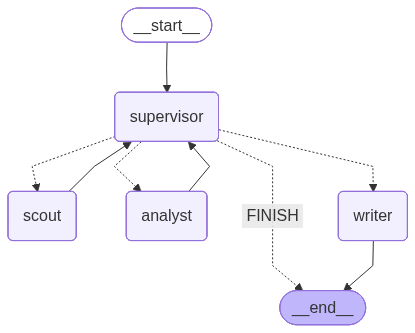

In [ ]:
from IPython.display import Image
Image(team_graph.get_graph().draw_mermaid_png())

In [ ]:
# ── Run the Multi-Agent Team ───────────────────────────────────────────────────
console.print(Panel(
    "[bold]Running 3-agent research team on Malaysian tech careers...[/bold]\n"
    "[dim]Supervisor → Scout → Analyst → Writer[/dim]",
    title="[bold red]Exercise E · Multi-Agent System[/bold red]",
    border_style="red"
))
console.print()

initial_state: TeamState = {
    "messages":     [],
    "topic":        TOPIC,
    "raw_research": "",
    "analysis":     "",
    "salary_data":  {},
    "final_report": "",
    "next_agent":   "",
    "iterations":   0,
}

final_state = team_graph.invoke(initial_state, {"recursion_limit": 25})

console.print()
console.print(Panel(
    f"[green]✓[/green] Pipeline complete in [bold]{final_state['iterations']}[/bold] supervisor decisions\n"
    f"Raw research: [bold]{len(final_state['raw_research']):,}[/bold] chars\n"
    f"Analysis: [bold]{len(final_state['analysis']):,}[/bold] chars\n"
    f"Final report: [bold]{len(final_state['final_report']):,}[/bold] chars",
    title="[bold green]✅ Team Summary[/bold green]",
    border_style="green", expand=False
))


╭──────────────────────────────── Exercise E · Multi-Agent System ─────────────────────────────────╮
│ Running 3-agent research team on Malaysian tech careers...                                       │
│ Supervisor → Scout → Analyst → Writer                                                            │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯

👔 Supervisor → scout: Begin broad web research to collect current data and credible sources on 
tech careers and AI job market for computer science graduates in Malaysia and Southeast Asia.

🔭 Scout searching the web...

✓ Scout gathered 11,559 chars

👔 Supervisor → analyst: Analyze the collected data to synthesize trends, gaps, and demand for CS 
graduates in AI roles across Malaysia and Southeast Asia, and produce actionable insights.

🧪 Analyst deep-diving the data...

✓ Analyst produced 12,682 chars

👔 Supervisor → writer: With raw_research and analysis completed, proceed to the final polished 
report.

╭─────────────── ✅ Team Summary ───────────────╮
│ ✓ Pipeline complete in 3 supervisor decisions │
│ Raw research: 11,559 chars                    │
│ Analysis: 12,682 chars                        │
│ Final report: 10,384 chars                    │
╰───────────────────────────────────────────────╯

In [ ]:
# ── Render the final report ───────────────────────────────────────────────────
console.print()
console.print(Panel(
    Markdown(final_state["final_report"]),
    title="[bold red]📄 FINAL REPORT — Malaysian Tech Career Intelligence[/bold red]",
    subtitle="[dim]Produced by Scout + Analyst + Writer agents[/dim]",
    border_style="red",
    padding=(1, 3)
))


╭────────────────────── 📄 FINAL REPORT — Malaysian Tech Career Intelligence ──────────────────────╮
│                                                                                                  │
│   🇲🇾 Tech Careers & AI Job Market for Computer Science Graduates in Malaysia & Southeast Asia    │
│                                                                                                  │
│                                                                                                  │
│                                        Executive Summary                                         │
│                                                                                                  │
│    • Malaysia’s KL/Cyberjaya job market remains active for software, AI, data, and cloud         │
│      roles, with mid-level software engineers commonly earning RM5,600–RM7,500/month and         │
│      senior engineers often above RM10,000/month. Fresh grads can expect lower starting          │
│      offers, typically in the RM3,000–RM5,000/month range, depending on firm type and            │
│      location. (Sources: JobStreet Malaysia, Glassdoor KL, NodeFlair, Arc.dev)                   │
│    • AI-focused roles command a premium relative to general software engineering, with junior    │
│      AI engineers often around RM3,800–RM4,500/month, mid-level RM5,000–RM8,000/month, and       │
│      senior positions exceeding RM12,000/month in some firms. Annual figures cited by some       │
│      aggregators hover around the RM150k/year band for higher-seniority roles. (Sources:         │
│      Glassdoor KL AI Engineer pages; ERiSalary)                                                  │
│    • The Southeast Asia AI market is growing rapidly, with regional forecasts pointing to        │
│      sizable APAC/SEA AI markets by the 2030s and high single-digit to low-double-digit CAGR     │
│      in the 2020s–2030s. This underpins rising demand for AI/machine learning talent across      │
│      Malaysia and neighboring countries. (Sources: MarketDataForecast APAC/SEA AI Market;        │
│      Statista; regional briefing sources)                                                        │
│    • Government initiatives and ecosystem programs (MDEC, MyDIGITAL, TalentCorp) are actively    │
│      expanding AI skills pipelines, talent mobility, and incentives to attract and retain tech   │
│      talent in Malaysia, including public-private partnerships and large-scale upskilling        │
│      programs. (Sources: MDEC, TalentCorp, Oracle/MyDIGITAL collaborations)                      │
│    • The strongest near-term opportunities for fresh CS grads in Malaysia are KL-based ML/AI,    │
│      data engineering, and backend roles at scaleups and MNCs (e.g., Grab, AirAsia, Petronas     │
│      Digital), with remote/ASEAN-wide roles expanding the on-ramp for new graduates. (Sources:   │
│      company pages, sector analyses)                                                             │
│                                                                                                  │
│                                                                                                  │
│                         Top In-Demand Skills (table with demand/salary)                          │
│                                                                                                  │
│   Skill (Malaysia focus) | Demand Signal | Typical Salary Range (Malaysia, monthly) | Notes /    │
│   Sources                                                                                        │
│                                                                                                  │
│    • Software Engineer (Backend / Full-Stack) | High | RM5,600–RM7,500 (mid-level); RM10,000+    │
│      (senior) | KL-focused data show mid-level ranges around RM5.6k–RM7.5k; senior roles often   │
│      exceed RM10k. Public aggregators corroborate RM6.5k med

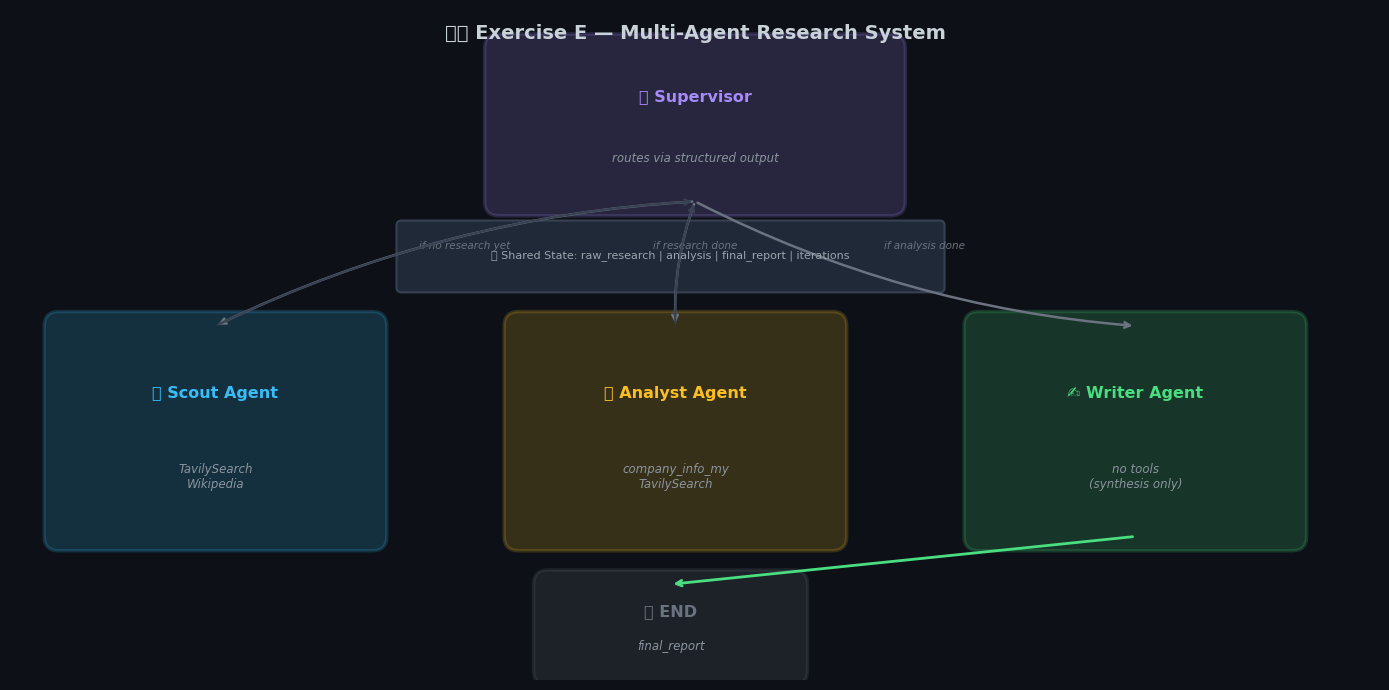

✓ Multi-agent architecture diagram saved


In [ ]:
# ── Multi-agent architecture visualisation ────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#0d1117')
ax.set_xlim(0, 14)
ax.set_ylim(0, 7)
ax.axis('off')

def draw_box(ax, x, y, w, h, label, sublabel, color, emoji):
    box = mpatches.FancyBboxPatch((x, y), w, h,
        boxstyle="round,pad=0.15", facecolor=color, alpha=0.18,
        edgecolor=color, linewidth=2.5)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.68, f"{emoji} {label}", ha='center', va='center',
            color=color, fontsize=11.5, fontweight='bold')
    ax.text(x+w/2, y+h*0.28, sublabel, ha='center', va='center',
            color='#8b949e', fontsize=8.5, style='italic')

# Supervisor
draw_box(ax, 5.0, 5.0, 4.0, 1.6, "Supervisor", "routes via structured output", "#a78bfa", "👔")

# Agents
draw_box(ax, 0.5, 1.5, 3.2, 2.2, "Scout Agent", "TavilySearch\nWikipedia", "#38bdf8", "🔭")
draw_box(ax, 5.2, 1.5, 3.2, 2.2, "Analyst Agent", "company_info_my\nTavilySearch", "#fbbf24", "🧪")
draw_box(ax, 9.9, 1.5, 3.2, 2.2, "Writer Agent", "no tools\n(synthesis only)", "#4ade80", "✍️")

# END
draw_box(ax, 5.5, 0.1, 2.5, 0.9, "END", "final_report", "#6b7280", "🏁")

# Arrows: Supervisor → Agents
for (x1, y1), (x2, y2), label in [
    ((7.0, 5.0), (2.1, 3.7), "if no research yet"),
    ((7.0, 5.0), (6.8, 3.7), "if research done"),
    ((7.0, 5.0), (11.5, 3.7), "if analysis done"),
]:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle='->', color='#6b7280', lw=1.8,
                       connectionstyle='arc3,rad=0.1'))
    mx, my = (x1+x2)/2, (y1+y2)/2
    ax.text(mx+0.1, my+0.15, label, color='#6b7280', fontsize=7.5, style='italic', ha='center')

# Arrows: Agents → Supervisor (feedback loop)
for x in [2.1, 6.8]:
    ax.annotate('', xy=(7.0, 5.0), xytext=(x, 3.7),
        arrowprops=dict(arrowstyle='->', color='#374151', lw=1.5,
                       connectionstyle='arc3,rad=-0.1'))

# Writer → END
ax.annotate('', xy=(6.75, 1.0), xytext=(11.5, 1.5),
    arrowprops=dict(arrowstyle='->', color='#4ade80', lw=2))

# Shared state label
state_box = mpatches.FancyBboxPatch((4.0, 4.1), 5.5, 0.65,
    boxstyle="round,pad=0.05", facecolor='#1f2937', edgecolor='#374151', linewidth=1.5)
ax.add_patch(state_box)
ax.text(6.75, 4.43, "📦 Shared State: raw_research | analysis | final_report | iterations",
        ha='center', va='center', color='#9ca3af', fontsize=8)

ax.text(7.0, 6.75, "🇲🇾 Exercise E — Multi-Agent Research System",
        ha='center', va='center', color='#c9d1d9', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('exercise_e_architecture.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117', edgecolor='none')
plt.show()
print("✓ Multi-agent architecture diagram saved")


---
## 📚 Final Recap — The Full Learning Journey

| | A | B | C | D | E |
|---|---|---|---|---|---|
| **Real-time data** | ❌ | ❌ | ✅ | ✅ | ✅ |
| **Typed output** | ❌ | ✅ | ❌ (raw) | ❌ | ✅ (shared state) |
| **Tool use** | ❌ | ❌ | ✅ scripted | ✅ autonomous | ✅ per agent |
| **Who controls loop?** | You | You | You | Agent | Supervisor |
| **Memory / multi-turn** | ❌ | ❌ | ❌ | ✅ | ✅ |
| **Specialisation** | ❌ | ❌ | ❌ | ❌ | ✅ 3 agents |

### 🔑 Three Most Important Concepts to Internalize

1. **LCEL `|` pipe** — anything that implements `Runnable` can be composed with `|`. This is the foundation of all LangChain chains.

2. **`bind_tools` vs `create_react_agent`** — `bind_tools` just tells the LLM "these exist". `create_react_agent` builds a *graph* that actually *executes* the tools and loops back to the LLM.

3. **State in LangGraph** — every node receives the full `TypedDict` state and returns a *partial update*. The `add_messages` reducer appends messages rather than replacing them. Shared state is what allows specialist agents to pass information to each other.

### 🚀 What to Explore Next
- **LangSmith** — tracing and debugging for all 5 exercises
- **LangGraph Studio** — visual graph debugger
- **Streaming** — `agent.stream()` for real-time token output  
- **Human-in-the-loop** — `interrupt_before=["tools"]` to approve tool calls
- **RAG + Agents** — add a vectorstore tool for document retrieval


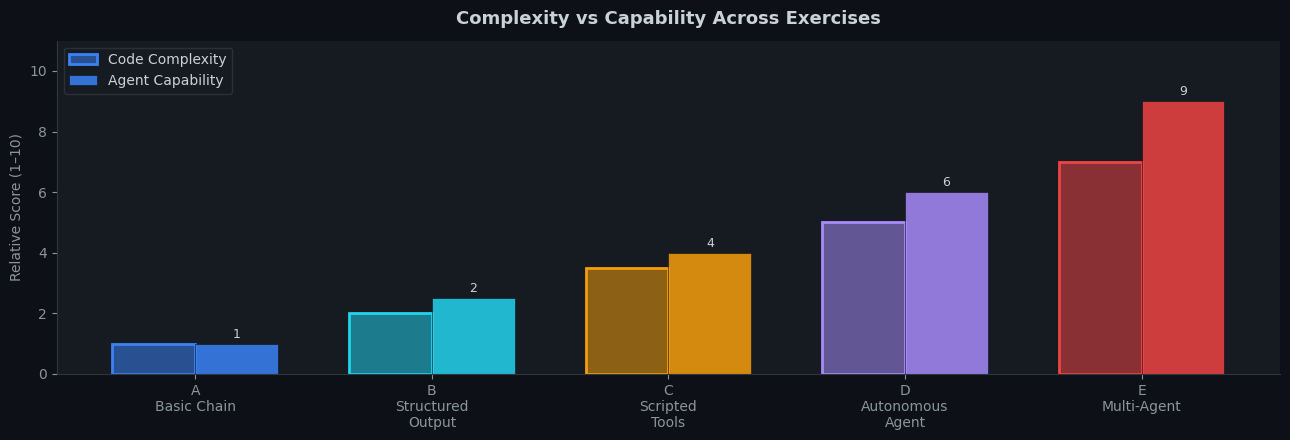

✓ All exercises complete! 🇲🇾


In [ ]:
# ── Final summary visualisation ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 4.5))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')

concepts = ["A\nBasic Chain", "B\nStructured\nOutput", "C\nScripted\nTools",
            "D\nAutonomous\nAgent", "E\nMulti-Agent"]
complexity = [1, 2, 3.5, 5, 7]
capability = [1, 2.5, 4, 6, 9]
colors = ["#3b82f6", "#22d3ee", "#f59e0b", "#a78bfa", "#ef4444"]

x = np.arange(len(concepts))
width = 0.35

bars1 = ax.bar(x - width/2, complexity, width, label='Code Complexity',
               color=[c + "88" for c in ["#3b82f6","#22d3ee","#f59e0b","#a78bfa","#ef4444"]],
               edgecolor=colors, linewidth=2)
bars2 = ax.bar(x + width/2, capability, width, label='Agent Capability',
               color=colors, alpha=0.85, edgecolor='#0d1117', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(concepts, color='#c9d1d9', fontsize=10)
ax.set_ylabel("Relative Score (1–10)", color='#8b949e', fontsize=10)
ax.set_title("Complexity vs Capability Across Exercises",
             color='#c9d1d9', fontsize=13, fontweight='bold', pad=12)
ax.tick_params(colors='#8b949e')
ax.spines['bottom'].set_color('#30363d')
ax.spines['left'].set_color('#30363d')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_facecolor('#161b22')
ax.legend(facecolor='#161b22', labelcolor='#c9d1d9', edgecolor='#30363d', fontsize=10)
ax.set_ylim(0, 11)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{bar.get_height():.0f}', ha='center', color='#c9d1d9', fontsize=9)

plt.tight_layout()
plt.savefig('exercise_summary_chart.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117', edgecolor='none')
plt.show()
print("✓ All exercises complete! 🇲🇾")
